# Oxygen mass transfer coefficient, $k_La$

When air is bubbled into liquid that starts with little oxygen, the dissolved oxygen concentration $C_{AL}$ rises toward its saturation value $C^*_{AL}$. If oxygen transfer follows a linear driving force model with mass transfer coefficient $k_La$, the rate of transfer is proportional to how far the liquid is from saturation, and

$$\ln\left(\frac{C^*_{AL} - C_{AL}}{C^*_{AL} - C_{AL0}}\right) = -k_La\,t$$

where $C_{AL0}$ is the dissolved oxygen at $t = 0$. A plot of the left side against time is a straight line with slope $-k_La$. This notebook fits that line to the readings between 20% and 80% of saturation for each run, reports $k_La$ in h$^{-1}$ with a 95% confidence interval, plots the model against your data, and plots the residuals so you can judge how well the straight line describes each run.

Because the equation uses only ratios of concentrations, readings in % air saturation can be used directly; there is no need to convert them to mg/L first. The probe is calibrated to 100% in the sparged reactor, so $C^*_{AL}$ is 100%.

**To use it:** put your data file in the same folder as this notebook and set the file name in the settings cell. Then choose **Run → Run All Cells** from the menu. The cells depend on one another, so they must run in order from the top; running only a later cell gives a `NameError`. After changing a setting, run all cells again.

In [39]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, t as t_dist

# Some notebook environments running Matplotlib 3.10 print harmless
# "parameter as float was deprecated" warnings when laying out figures.
warnings.filterwarnings("ignore", message=".*parameter as float was deprecated.*")

## 1. Settings

Change only this cell. The first column of the data file must be time, in seconds. Every other column holds the dissolved oxygen readings, in % air saturation, for one run and can have its own header, such as `Trial 1` or `600 rpm 1 L/min`. Runs of different lengths are fine: leave the unused cells at the bottom of a shorter run blank.

In [41]:
DATA_FILE = "massy.csv"

# Range of readings used in the fit, in % air saturation.
WINDOW_LOW = 20.0
WINDOW_HIGH = 80.0

# The fitted kLa values are also saved to this file for your spreadsheet.
RESULTS_FILE = "massyresults.csv"

# Run shown in the representative figure in Section 5. Type its column header
# exactly, such as "Trial 1". Leave it as "" to use the first run in the file.
REPRESENTATIVE_RUN = ""

# The representative figure is also saved to this file.
FIGURE_FILE = "kLa_representative_figure.png"

## 2. Load the data

In [43]:
if not os.path.exists(DATA_FILE):
    csv_files = sorted(f for f in os.listdir(".") if f.lower().endswith(".csv"))
    raise FileNotFoundError(
        f'Cannot find "{DATA_FILE}" in the folder this notebook is in.\n'
        f"CSV files in this folder: {', '.join(csv_files) if csv_files else 'none'}.\n"
        "Move your data file into this folder, or change DATA_FILE in the settings cell "
        "to match its name exactly."
    )
df = pd.read_csv(DATA_FILE)
df = df.dropna(axis="columns", how="all")         # ignore empty columns left over from Excel
C_STAR = 100.0   # the probe is calibrated to 100% in the sparged reactor, so saturation reads 100%
TIME_COLUMN = df.columns[0]                         # the first column is always time
run_columns = list(df.columns[1:])

runs = {}
for run in run_columns:
    rows = df[[TIME_COLUMN, run]].dropna()            # skip blank cells in shorter runs
    runs[run] = (rows[TIME_COLUMN].to_numpy(dtype=float),
                 rows[run].to_numpy(dtype=float))
    t_run, c_run = runs[run]
    print(f"{run}: {len(t_run)} points from {t_run.min():g} to {t_run.max():g} s, "
          f"reading {c_run.min():.1f} to {c_run.max():.1f}%")

(100, 1) : 188 points from 0 to 935 s, reading 6.0 to 80.1%
(250, 1) : 129 points from 0 to 640 s, reading 2.3 to 80.1%


## 3. Fit $k_La$ for each run

For each run, the notebook keeps the readings between 20% and 80% of saturation, calculates $\ln\left[(C^*_{AL} - C_{AL})/(C^*_{AL} - C_{AL0})\right]$, and fits a straight line to it against time. $k_La$ is the negative of the slope. The 95% confidence interval is the standard error of the slope multiplied by the t value for the number of points minus two, the same calculation as for any straight-line fit.

This interval reflects only how closely one run's points scatter around its line. Repeated runs at the same agitation and gas flow give a better measure of how reproducible $k_La$ is. Put each repeated run in its own column so that each is fitted separately; averaging the readings before fitting hides the run-to-run spread.

The notebook also reports $1/k_La$, the characteristic time for oxygen transfer, in seconds so you can compare it directly with your electrode response time $\tau_E$. A slow probe makes the fitted $k_La$ too low. The error is less than about 2% when $\tau_E$ is no more than one-fifth of $1/k_La$, but it grows quickly as $\tau_E$ gets larger: about 7% when $\tau_E$ is one-third of $1/k_La$ and about 35% when $\tau_E$ equals $1/k_La$.

In [45]:
results = {}
for run, (t_run, c_run) in runs.items():
    c0 = c_run[0]
    in_window = (c_run >= WINDOW_LOW) & (c_run <= WINDOW_HIGH) & (c_run < C_STAR)
    if in_window.sum() < 3 or c0 >= C_STAR:
        print(f"{run}: fewer than three readings between {WINDOW_LOW:g} and {WINDOW_HIGH:g}%, so it was not fitted.")
        continue
    t_fit = t_run[in_window]
    y_fit = np.log((C_STAR - c_run[in_window]) / (C_STAR - c0))
    line = linregress(t_fit, y_fit)
    half_width = t_dist.ppf(0.975, len(t_fit) - 2) * line.stderr
    results[run] = {
        "kLa_s": -line.slope, "ci_s": half_width, "intercept": line.intercept,
        "r2": line.rvalue**2, "c0": c0, "t_fit": t_fit, "y_fit": y_fit,
        "residuals": y_fit - (line.intercept + line.slope * t_fit),
    }

print("Best-fit kLa with 95% confidence intervals\n")
rows = []
for run, r in results.items():
    kLa_h, ci_h = 3600 * r["kLa_s"], 3600 * r["ci_s"]
    print(f"{run}:  kLa = {kLa_h:.2f} ± {ci_h:.2f} 1/h   (1/kLa = {1 / r['kLa_s']:.0f} s, "
          f"{len(r['t_fit'])} points from {r['t_fit'][0]:g} to {r['t_fit'][-1]:g} s, R² = {r['r2']:.4f})")
    rows.append({"Trial": run, "kLa (1/h)": kLa_h, "95% CI kLa (1/h)": ci_h,
                 "1/kLa (s)": 1 / r["kLa_s"], "Points fitted": len(r["t_fit"]),
                 "R-squared (transformed)": r["r2"]})
pd.DataFrame(rows).to_csv(RESULTS_FILE, index=False)
print(f"\nResults saved to {RESULTS_FILE}.")

Best-fit kLa with 95% confidence intervals

(100, 1) :  kLa = 7.04 ± 0.05 1/h   (1/kLa = 511 s, 144 points from 215 to 930 s, R² = 0.9985)
(250, 1) :  kLa = 9.78 ± 0.03 1/h   (1/kLa = 368 s, 103 points from 125 to 635 s, R² = 0.9998)

Results saved to massyresults.csv.


## 4. Model and data

Each line is the fitted model converted back to dissolved oxygen, drawn over the 20% to 80% range used in the fit, which is shaded. Readings outside that range are shown for reference.

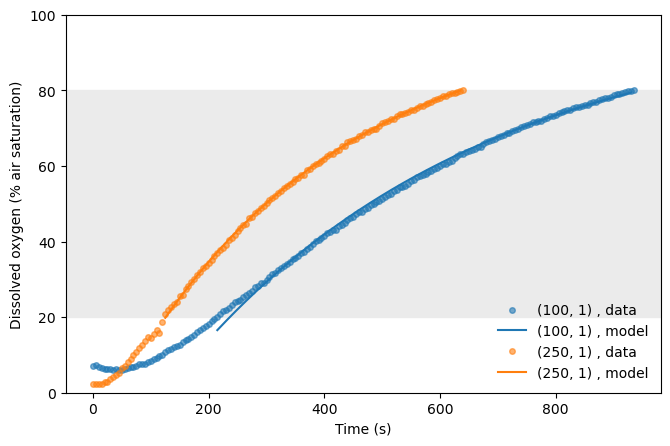

In [47]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhspan(WINDOW_LOW, WINDOW_HIGH, color="0.92", zorder=0)
for i, (run, r) in enumerate(results.items()):
    t_run, c_run = runs[run]
    color = f"C{i}"
    t_smooth = np.linspace(r["t_fit"].min(), r["t_fit"].max(), 300)
    c_model = C_STAR - (C_STAR - r["c0"]) * np.exp(r["intercept"] - r["kLa_s"] * t_smooth)
    ax.plot(t_run, c_run, "o", markersize=4, alpha=0.6, color=color, label=f"{run}, data")
    ax.plot(t_smooth, c_model, "-", color=color, label=f"{run}, model")

ax.set_xlabel("Time (s)")
ax.set_ylabel("Dissolved oxygen (% air saturation)")
ax.set_ylim(0, 100)
ax.legend(frameon=False, loc="lower right")
fig.subplots_adjust(left=0.12, right=0.97, bottom=0.12, top=0.96)
plt.show()

## 5. Representative figure

This is a representative figure for one run, with the readings used in the fit shown as filled symbols, the readings outside the 20% to 80% range as open symbols, and the fitted model as a line. Choose the run in the settings cell with `REPRESENTATIVE_RUN`. The figure has no title because the caption you write in your report takes its place; state the run's agitation rate, gas flow rate and $k_La$ in that caption. The figure is saved at print resolution to the file named in `FIGURE_FILE`, in the same folder as this notebook.

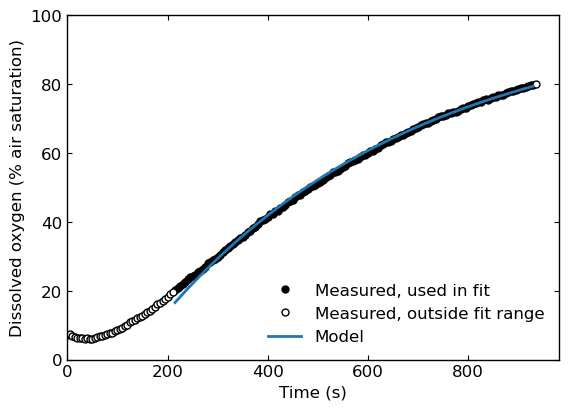

(100, 1) : kLa = 7.04 ± 0.05 1/h
Figure saved to kLa_representative_figure.png.


In [49]:
if REPRESENTATIVE_RUN == "":
    rep_run = next(iter(results))
elif REPRESENTATIVE_RUN in results:
    rep_run = REPRESENTATIVE_RUN
else:
    raise ValueError(
        f'"{REPRESENTATIVE_RUN}" is not one of the fitted runs. '
        f"Set REPRESENTATIVE_RUN to one of: {', '.join(results)}."
    )

r = results[rep_run]
t_run, c_run = runs[rep_run]
used = (c_run >= WINDOW_LOW) & (c_run <= WINDOW_HIGH)
t_smooth = np.linspace(r["t_fit"].min(), r["t_fit"].max(), 300)
c_model = C_STAR - (C_STAR - r["c0"]) * np.exp(r["intercept"] - r["kLa_s"] * t_smooth)

with plt.rc_context({"font.size": 12, "axes.linewidth": 1.0}):
    fig, ax = plt.subplots(figsize=(6.0, 4.2))
    ax.plot(t_run[used], c_run[used], "o", markersize=5, color="black",
            label="Measured, used in fit")
    ax.plot(t_run[~used], c_run[~used], "o", markersize=5, markerfacecolor="white",
            markeredgecolor="black", label="Measured, outside fit range")
    ax.plot(t_smooth, c_model, "-", color="C0", linewidth=2, label="Model")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Dissolved oxygen (% air saturation)")
    ax.set_xlim(left=0)
    ax.set_ylim(0, 100)
    ax.tick_params(direction="in", top=True, right=True)
    ax.legend(frameon=False, loc="lower right")
    fig.subplots_adjust(left=0.14, right=0.96, bottom=0.14, top=0.96)
    fig.savefig(FIGURE_FILE, dpi=300)
    plt.show()

print(f"{rep_run}: kLa = {3600 * r['kLa_s']:.2f} ± {3600 * r['ci_s']:.2f} 1/h")
print(f"Figure saved to {FIGURE_FILE}.")

## 6. Straight-line fit

These are the transformed readings from the 20% to 80% range with the fitted line for each run. If the linear driving force model holds, the points fall on a straight line.

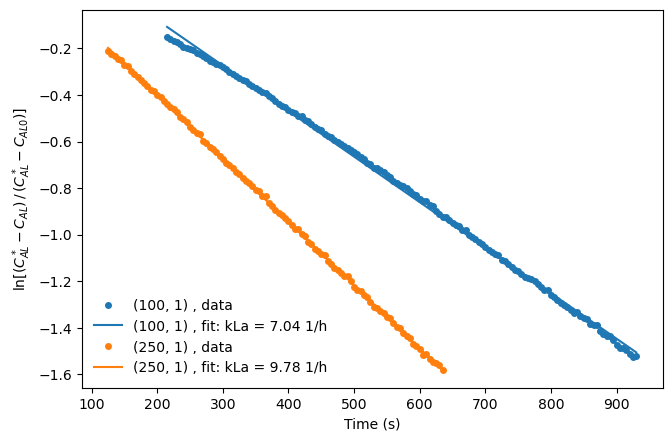

In [51]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, (run, r) in enumerate(results.items()):
    color = f"C{i}"
    ax.plot(r["t_fit"], r["y_fit"], "o", markersize=4, color=color, label=f"{run}, data")
    t_line = np.array([r["t_fit"].min(), r["t_fit"].max()])
    ax.plot(t_line, r["intercept"] - r["kLa_s"] * t_line, "-", color=color,
            label=f"{run}, fit: kLa = {3600 * r['kLa_s']:.2f} 1/h")

ax.set_xlabel("Time (s)")
ax.set_ylabel(r"$\ln[(C^*_{AL} - C_{AL})\,/\,(C^*_{AL} - C_{AL0})]$")
ax.legend(frameon=False, loc="lower left")
fig.subplots_adjust(left=0.14, right=0.97, bottom=0.12, top=0.96)
plt.show()

## 7. Residuals

A residual is the transformed reading minus the fitted line at the same time:

$$\text{residual} = y - \left(b - k_La\,t\right), \qquad y = \ln\left(\frac{C^*_{AL} - C_{AL}}{C^*_{AL} - C_{AL0}}\right)$$

where $y$ is the transformed reading plotted in Section 6 and $b$ is the intercept of the fitted line. If the linear driving force model describes your run, the residuals are small and scatter randomly above and below zero.

A pattern means the model is missing something. A bow, with residuals negative at both ends of the window and positive in the middle, means the transformed points curve instead of following a straight line. This can happen when oxygen transfer starts slowly, for example while the gas in the vessel and lines changes over from nitrogen to air, or when the probe lags behind the liquid. A single residual that jumps and returns marks an event such as a bubble on the probe membrane. All panels share the same vertical scale, so you can see whether a pattern appears in every run or only one.

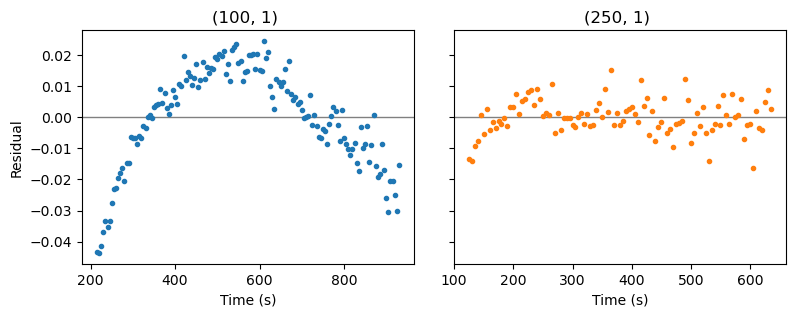

In [53]:
n_runs = len(results)
n_cols = min(n_runs, 3)
n_rows = int(np.ceil(n_runs / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows),
                         sharey=True, squeeze=False)

for ax, (i, (run, r)) in zip(axes.flat, enumerate(results.items())):
    ax.axhline(0.0, color="gray", linewidth=1)
    ax.plot(r["t_fit"], r["residuals"], "o", markersize=3, color=f"C{i}")
    ax.set_title(run)
    ax.set_xlabel("Time (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("Residual (measured − model)")
for ax in list(axes.flat)[n_runs:]:
    ax.set_visible(False)

fig.subplots_adjust(left=0.1, right=0.98, bottom=0.17 if n_rows == 1 else 0.1,
                    top=0.9 if n_rows == 1 else 0.94, wspace=0.12, hspace=0.45)
plt.show()